### Exercise 4.35

H_0: mu_125 = mu_160 = mu_200

H_1: At least one flow-rate mean differs

In [2]:
flow_125 = [2.7, 2.6, 4.6, 3.2, 3.0, 3.8]
flow_160 = [4.6, 4.9, 5.0, 4.3, 3.6, 4.2]
flow_200 = [4.6, 2.9, 3.4, 3.5, 4.1, 5.1]

from scipy import stats
f_stat, p_value = stats.f_oneway(flow_125, flow_160, flow_200)
print("F statistic:", f_stat)
print("P-value:", p_value)

F statistic: 3.7074829931972793
P-value: 0.04916418130300425


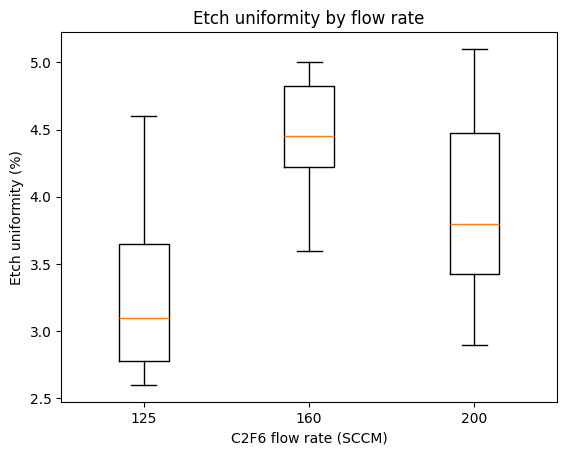

In [3]:
import matplotlib.pyplot as plt

plt.boxplot(
    [flow_125, flow_160, flow_200],
    tick_labels=["125", "160", "200"]
)
plt.xlabel("C2F6 flow rate (SCCM)")
plt.ylabel("Etch uniformity (%)")
plt.title("Etch uniformity by flow rate")
plt.show()

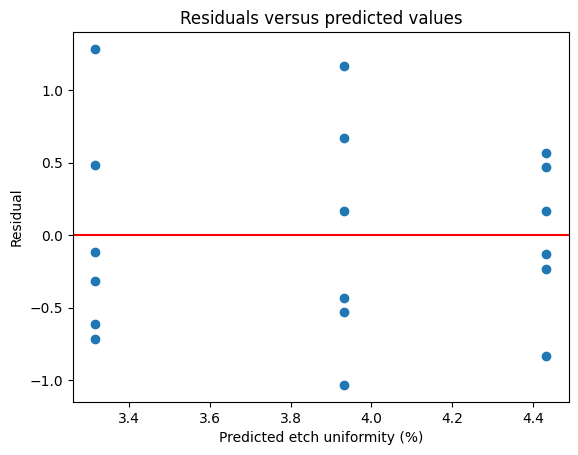

In [8]:
import numpy as np

groups = [flow_125, flow_160, flow_200]
predicted = []
residuals = []
for group in groups:
    group_mean = np.mean(group)
    for value in group:
        predicted.append(group_mean)
        residuals.append(value - group_mean)

plt.scatter(predicted, residuals)
plt.axhline(0, color="red")
plt.xlabel("Predicted etch uniformity (%)")
plt.ylabel("Residual")
plt.title("Residuals versus predicted values")
plt.show()

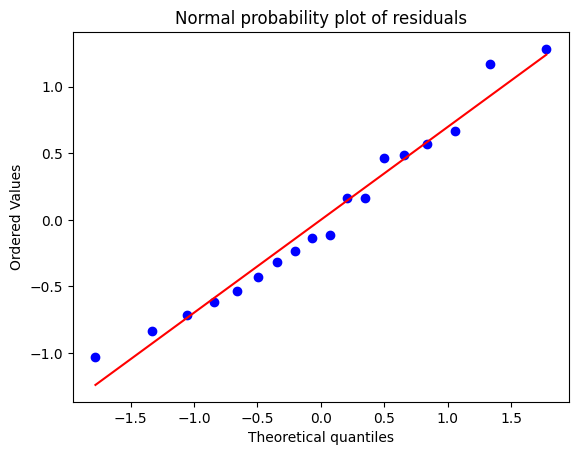

In [9]:
fig, ax = plt.subplots()
stats.probplot(residuals, plot=ax)
ax.set_title("Normal probability plot of residuals")
plt.show()

In [13]:
import pandas as pd
import statsmodels.api as sm
from statsmodels.formula.api import ols
data = pd.DataFrame({
    "flow": ["125"] * 6 + ["160"] * 6 + ["200"] * 6,
    "uniformity": flow_125 + flow_160 + flow_200
})
model = ols("uniformity ~ C(flow)", data=data).fit()
anova_table = sm.stats.anova_lm(model, typ=1)

print(anova_table)

            df    sum_sq   mean_sq         F    PR(>F)
C(flow)    2.0  3.754444  1.877222  3.707483  0.049164
Residual  15.0  7.595000  0.506333       NaN       NaN


### Exercise 4.36



In [14]:
from statsmodels.stats.multicomp import pairwise_tukeyhsd
tukey = pairwise_tukeyhsd(
    endog=data["uniformity"],
    groups=data["flow"],
    alpha=0.05
)
print(tukey)

Multiple Comparison of Means - Tukey HSD, FWER=0.05
group1 group2 meandiff p-adj   lower  upper  reject
---------------------------------------------------
   125    160   1.1167 0.0397  0.0496 2.1838   True
   125    200   0.6167 0.3183 -0.4504 1.6838  False
   160    200     -0.5 0.4617 -1.5671 0.5671  False
---------------------------------------------------


### Exercise 4.53

In [4]:
import numpy as np
from scipy import stats

n = 15
sample_mean = 31.4
mu_0 = 30
sigma = 1.3

se = sigma / np.sqrt(n)
z = (sample_mean - mu_0) / se
p = 2 * stats.norm.sf(abs(z))

print("SE mean:", se)
print("Z statistic:", z)
print("Two-sided P-value:", p)

SE mean: 0.33565855667130945
Z statistic: 4.170905142069522
Two-sided P-value: 3.0339214284281195e-05


In [5]:
lower = sample_mean - 1.96 * se
upper = sample_mean + 1.96 * se

print("95% CI:", lower, upper)

95% CI: 30.74210922892423 32.05789077107576


In [6]:
one_sided_p = stats.norm.sf(z)
print("One-sided P-value:", one_sided_p)

One-sided P-value: 1.5169607142140598e-05


### Exercise 4.47


Response variable: brake horsepower

Predictors: rpm, road octane number, and compression

The model is:
horsepower = B_0 + B_1(rpm) + B_2(octane) + B_3(compression) + error

For the overall regression test:
H_0: B_1 = B_2 = B_3 = 0
H_1: At least one of these coefficients is not zero

I will use a significance level of = 0.05. For the model, I assume some independent errors
with constant variance and a roughly normal distribution.

In [1]:
import pandas as pd
import statsmodels.api as sm

engine = pd.DataFrame({
    "horsepower": [225, 212, 229, 222, 219, 278, 246, 237, 233, 224, 223, 230],
    "rpm": [2000, 1800, 2400, 1900, 1600, 2500, 3000, 3200, 2800, 3400, 1800, 2500],
    "octane": [90, 94, 88, 91, 86, 96, 94, 90, 88, 86, 90, 89],
    "compression": [100, 95, 110, 96, 100, 110, 98, 100, 105, 97, 100, 104]
})

X = sm.add_constant(engine[["rpm", "octane", "compression"]])
y = engine["horsepower"]

model = sm.OLS(y, X).fit()
print(model.summary())

                            OLS Regression Results                            
Dep. Variable:             horsepower   R-squared:                       0.807
Model:                            OLS   Adj. R-squared:                  0.734
Method:                 Least Squares   F-statistic:                     11.12
Date:                Mon, 28 Sep 2026   Prob (F-statistic):            0.00317
Time:                        00:20:32   Log-Likelihood:                -40.708
No. Observations:                  12   AIC:                             89.42
Df Residuals:                       8   BIC:                             91.36
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const        -266.0312     92.674     -2.871      